# Proyecto 3: nivel de generación solar, Planta 1
## Avance de calidad de datos y análisis exploratorio (EDA)

**Analítica de Datos I - Universidad Icesi - 11 de noviembre de 2026**  
Integrantes: pendientes.

Este avance desarrolla la comprensión de los datos y una propuesta revisable de preparación, siguiendo CRISP-DM. Todas las gráficas y tablas se generan a partir del CSV local. Las observaciones descriptivas son una propuesta para revisión de los tres integrantes.

**Disponible:** `Plant_1_Generation_Data.csv`. **Pendiente:** `Plant_1_Weather_Sensor_Data.csv`. Por eso el avance cubre la generación; las relaciones con irradiación y temperaturas no se presentan como terminadas. No se entrenan modelos ni se modifican los CSV originales.

**Contenido:** problema y datos; integridad y cobertura; potencia de la planta; distribuciones y patrones temporales; escala DC/AC; candidatos atípicos; memoria temporal; pendientes, decisiones y registro de IA.

## 1. Problema y alcance

La empresa de operación y mantenimiento necesita anticipar si la generación de la planta estará en nivel bajo, medio o alto **15 minutos después** para apoyar su planificación. La variable continua que posteriormente dará origen a las clases es:

$$P(s)=\sum_{i=1}^{22} AC\_POWER_i(s).$$

Una fila del dataset de generación representa **un inversor en un instante**, no toda la planta. La fuente describe 34 días de mediciones de dos plantas en India; nuestro caso empresarial es colombiano y utiliza solo la Planta 1. No se asigna una zona horaria al CSV porque sus fechas no la incluyen.

Fuente de los datos: [Ani Kannal, Solar Power Generation Data, Kaggle](https://www.kaggle.com/anikannal/solar-power-generation-data). Requisitos: PDF de Proyecto 3 en `../consigna/`, especialmente páginas 6-8 y anexos A/B; guía HTML de series de tiempo en esa misma carpeta. La investigación bibliográfica y las preguntas de negocio definitivas de la Tarea 1 siguen pendientes.

La consigna, páginas 3 y 6, pide **generación más sensor meteorológico**. En la captura de la tabla de datos, la fila «1 y 3» también enumera ambos CSV. El sensor contiene irradiación, temperatura ambiente y temperatura del módulo. Su ausencia limita este avance.

## 2. Entorno y lectura reproducible

Abrir este notebook con el Python de `.venv` y ejecutar todas las celdas. Las rutas funcionan desde la raíz del proyecto o desde `notebooks/`. La semilla se fija en 42 para cualquier muestreo gráfico; las tablas de diagnóstico usan todos los registros correspondientes.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'consigna').is_dir() and (p / 'notebooks').is_dir()
             and (p / 'requirements.txt').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Abrir el notebook dentro de la carpeta Proyecto.')
DATOS = RAIZ / 'datos'
RANDOM_STATE = 42
INVERSORES_ESPERADOS = 22  # Consigna específica, página 1.
FRECUENCIA = '15min'
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
AZUL, NARANJA, ROJO = '#315C83', '#D68C32', '#B84A48'
print('Python:', platform.python_version(), '| Entorno virtual:', sys.prefix != sys.base_prefix)
display(pd.Series({p: version(p) for p in ['pandas', 'numpy', 'matplotlib',
                 'seaborn', 'scikit-learn', 'statsmodels']}, name='Versión').to_frame())

Python: 3.14.3 | Entorno virtual: True


,Versión
pandas,3.1.1
numpy,2.5.4
matplotlib,3.11.2
seaborn,0.13.2
scikit-learn,1.9.1
statsmodels,0.15.0


In [2]:
archivo_generacion = DATOS / 'Plant_1_Generation_Data.csv'
archivo_sensor = DATOS / 'Plant_1_Weather_Sensor_Data.csv'
if not archivo_generacion.is_file():
    raise FileNotFoundError('Colocar Plant_1_Generation_Data.csv directamente en datos/.')
original = pd.read_csv(archivo_generacion)
generacion = original.copy(deep=True)
requeridas = {'DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER',
              'DAILY_YIELD', 'TOTAL_YIELD'}
if not requeridas.issubset(generacion.columns):
    raise ValueError('El CSV no tiene las siete columnas esperadas de generación.')
sha_generacion = hashlib.sha256(archivo_generacion.read_bytes()).hexdigest()
print('Archivo:', archivo_generacion.name, '| Filas y columnas:', original.shape)
print('SHA-256:', sha_generacion)
print('Sensor disponible:', archivo_sensor.is_file())
display(original.head())
estructura = pd.DataFrame({'tipo_original': original.dtypes.astype(str),
                          'nulos': original.isna().sum(),
                          'valores_distintos': original.nunique()})
display(estructura)
display(original.select_dtypes('number').describe().T.round(3))

Archivo: Plant_1_Generation_Data.csv | Filas y columnas: (68778, 7)
SHA-256: 882f75f1c295946633617646cc92343ddb6fb821a2546c82f7e5cc737a13624e
Sensor disponible: False


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


,tipo_original,nulos,valores_distintos
DATE_TIME,str,0,3158
PLANT_ID,int64,0,1
SOURCE_KEY,str,0,22
DC_POWER,float64,0,32909
AC_POWER,float64,0,32686
DAILY_YIELD,float64,0,29900
TOTAL_YIELD,float64,0,37267


,count,mean,std,min,25%,50%,75%,max
PLANT_ID,68778.0,4135001.000,0.000,4135001.0,4135001.000,4135001.000,4135001.000,4135001.000
DC_POWER,68778.0,3147.426,4036.457,0.0,0.000,429.000,6366.964,14471.125
AC_POWER,68778.0,307.803,394.396,0.0,0.000,41.494,623.619,1410.950
DAILY_YIELD,68778.0,3295.969,3145.178,0.0,0.000,2658.714,6274.000,9163.000
TOTAL_YIELD,68778.0,6978711.761,416271.983,6183645.0,6512002.536,7146685.000,7268705.906,7846821.000


**Lectura de la tabla.** `SOURCE_KEY` identifica el inversor; `PLANT_ID` identifica la planta. Tener una sola planta o muchas filas con la misma fecha no indica un error: es necesario comprobar la clave compuesta fecha-inversor. `DAILY_YIELD` y `TOTAL_YIELD` son acumulados; no se suman como si fueran potencia instantánea ni se usarán como predictores. Los ceros de potencia se mantienen para distinguir registros observados de huecos de comunicación.

## 3. Calidad: fechas, claves y rangos

El formato del CSV de generación es día-mes-año. Se convierte explícitamente y se cuentan los fallos, en lugar de ocultarlos. La frecuencia se evalúa sobre **instantes únicos**: hacerlo sobre las 68 mil filas por inversor produciría muchos intervalos de cero minutos que son esperables.

In [3]:
generacion['DATE_TIME'] = pd.to_datetime(original['DATE_TIME'],
                                        format='%d-%m-%Y %H:%M', errors='coerce')
fechas_invalidas = int(generacion['DATE_TIME'].isna().sum())
duplicados_fila = int(original.duplicated().sum())
duplicados_clave = int(generacion.duplicated(['DATE_TIME', 'SOURCE_KEY']).sum())
display(pd.Series({'Fechas inválidas': fechas_invalidas,
                   'Filas idénticas repetidas': duplicados_fila,
                   'Claves fecha-inversor repetidas': duplicados_clave,
                   'Plantas distintas': generacion['PLANT_ID'].nunique(),
                   'Inversores distintos': generacion['SOURCE_KEY'].nunique()},
                  name='Cantidad').to_frame())
if fechas_invalidas or duplicados_clave:
    raise ValueError('Revisar fechas o claves duplicadas antes de sumar la potencia.')
if generacion['PLANT_ID'].nunique() != 1 or generacion['SOURCE_KEY'].nunique() != 22:
    raise ValueError('La planta o el número de inversores no coincide con la consigna.')
generacion = generacion.sort_values(['DATE_TIME', 'SOURCE_KEY']).reset_index(drop=True)
instantes = pd.DatetimeIndex(generacion['DATE_TIME'].drop_duplicates().sort_values())
display(instantes.to_series().diff().value_counts().sort_index().rename('Intervalos').to_frame())
limites_observados = pd.DataFrame({
    'mínimo': generacion[['AC_POWER', 'DC_POWER']].min(),
    'máximo': generacion[['AC_POWER', 'DC_POWER']].max(),
    'negativos': (generacion[['AC_POWER', 'DC_POWER']] < 0).sum(),
    'ceros': (generacion[['AC_POWER', 'DC_POWER']] == 0).sum(),
})
display(limites_observados)

,Cantidad
Fechas inválidas,0
Filas idénticas repetidas,0
Claves fecha-inversor repetidas,0
Plantas distintas,1
Inversores distintos,22


,Intervalos
DATE_TIME,
0 days 00:15:00,3148
0 days 00:30:00,2
0 days 00:45:00,1
0 days 01:00:00,1
0 days 01:45:00,1
0 days 03:00:00,1
0 days 04:15:00,1
0 days 08:00:00,1
0 days 09:00:00,1


,mínimo,máximo,negativos,ceros
AC_POWER,0.0,1410.950,0,31951
DC_POWER,0.0,14471.125,0,31951


In [4]:
display(Markdown(
    f'**Observación.** El periodo va de **{instantes.min():%d-%m-%Y %H:%M}** '
    f'a **{instantes.max():%d-%m-%Y %H:%M}**. '
    f'Hay **{int(original.isna().sum().sum()):,} celdas nulas**, '
    f'**{duplicados_fila} filas idénticas** y **{duplicados_clave} claves repetidas**. '
    'Estos conteos no detectan las filas que nunca llegaron: la siguiente sección construye la rejilla esperada. '
    'Sin una capacidad nominal verificada no se fija un límite superior físico arbitrario para la potencia.'
))

**Observación.** El periodo va de **15-05-2020 00:00** a **17-06-2020 23:45**. Hay **0 celdas nulas**, **0 filas idénticas** y **0 claves repetidas**. Estos conteos no detectan las filas que nunca llegaron: la siguiente sección construye la rejilla esperada. Sin una capacidad nominal verificada no se fija un límite superior físico arbitrario para la potencia.

## 4. Construcción de la planta y cobertura de 15 minutos

Se conservan dos columnas diferentes:

- `AC_OBSERVADA_KW`: suma de los inversores que efectivamente reportaron.
- `AC_PLANTA_KW`: esa suma **solo cuando reportan los 22 inversores y sus 22 valores AC están disponibles**.

La segunda columna es una propuesta conservadora para el EDA: evita interpretar una suma parcial como potencia de toda la planta. Los valores originales y la suma observada se conservan. Los instantes incompletos no se corrigen ni se multiplican automáticamente por 22/n. No se imputa potencia ni se elimina una fila original.

In [5]:
grupo = generacion.groupby('DATE_TIME')
planta_observada = grupo.agg(
    AC_OBSERVADA_KW=('AC_POWER', lambda s: s.sum(min_count=1)),
    INVERSORES_REPORTANDO=('SOURCE_KEY', 'nunique'),
    VALORES_AC=('AC_POWER', 'count'),
).sort_index()
inicio = instantes.min().normalize()
fin = instantes.max().normalize() + pd.Timedelta(hours=23, minutes=45)
rejilla = pd.date_range(inicio, fin, freq=FRECUENCIA, name='DATE_TIME')
if len(instantes.difference(rejilla)):
    raise ValueError('Existen fechas fuera de la rejilla exacta de 15 minutos; revisarlas.')
planta = planta_observada.reindex(rejilla)
planta['REGISTRO_PRESENTE'] = planta.index.isin(instantes)
planta['GENERACION_COMPLETA'] = ((planta['INVERSORES_REPORTANDO'] == 22)
                                & (planta['VALORES_AC'] == 22))
planta['AC_PLANTA_KW'] = planta['AC_OBSERVADA_KW'].where(planta['GENERACION_COMPLETA'])
planta['INCOMPLETO'] = planta['REGISTRO_PRESENTE'] & ~planta['GENERACION_COMPLETA']
serie = planta['AC_PLANTA_KW']
resumen = pd.Series({
    'Filas de generación': len(generacion),
    'Días del periodo': len(pd.date_range(inicio.normalize(), fin.normalize(), freq='D')),
    'Instantes esperados': len(rejilla),
    'Instantes recibidos': len(instantes),
    'Instantes sin registros': int((~planta['REGISTRO_PRESENTE']).sum()),
    'Instantes recibidos incompletos': int(planta['INCOMPLETO'].sum()),
    'Instantes con 22 inversores y AC válido': int(planta['GENERACION_COMPLETA'].sum()),
    'Registros fecha-inversor esperados': len(rejilla) * INVERSORES_ESPERADOS,
    'Registros fecha-inversor ausentes': len(rejilla) * INVERSORES_ESPERADOS - len(generacion),
}, name='Cantidad')
display(resumen.to_frame())
display(planta.loc[planta['INCOMPLETO'], ['INVERSORES_REPORTANDO', 'AC_OBSERVADA_KW',
                                         'AC_PLANTA_KW']].head(10))

,Cantidad
Filas de generación,68778
Días del periodo,34
Instantes esperados,3264
Instantes recibidos,3158
Instantes sin registros,106
Instantes recibidos incompletos,101
Instantes con 22 inversores y AC válido,3057
Registros fecha-inversor esperados,71808
Registros fecha-inversor ausentes,3030


,INVERSORES_REPORTANDO,AC_OBSERVADA_KW,AC_PLANTA_KW
DATE_TIME,,,
2020-05-15 00:00:00,21.0,0.0,NaN
2020-05-15 00:15:00,21.0,0.0,NaN
2020-05-15 00:30:00,21.0,0.0,NaN
2020-05-15 00:45:00,21.0,0.0,NaN
2020-05-15 01:15:00,21.0,0.0,NaN
2020-05-15 01:30:00,21.0,0.0,NaN
2020-05-15 02:00:00,21.0,0.0,NaN
2020-05-15 02:15:00,21.0,0.0,NaN
2020-05-15 02:30:00,21.0,0.0,NaN


,ausentes,incompletos,completos,cobertura_completa_%
DATE_TIME,,,,
2020-05-15,3,29,64,66.67
2020-05-16,8,1,87,90.62
2020-05-17,0,0,96,100.00
2020-05-18,0,0,96,100.00
2020-05-19,3,14,79,82.29
2020-05-20,20,0,76,79.17
2020-05-21,31,8,57,59.38
2020-05-22,0,7,89,92.71
2020-05-23,7,0,89,92.71


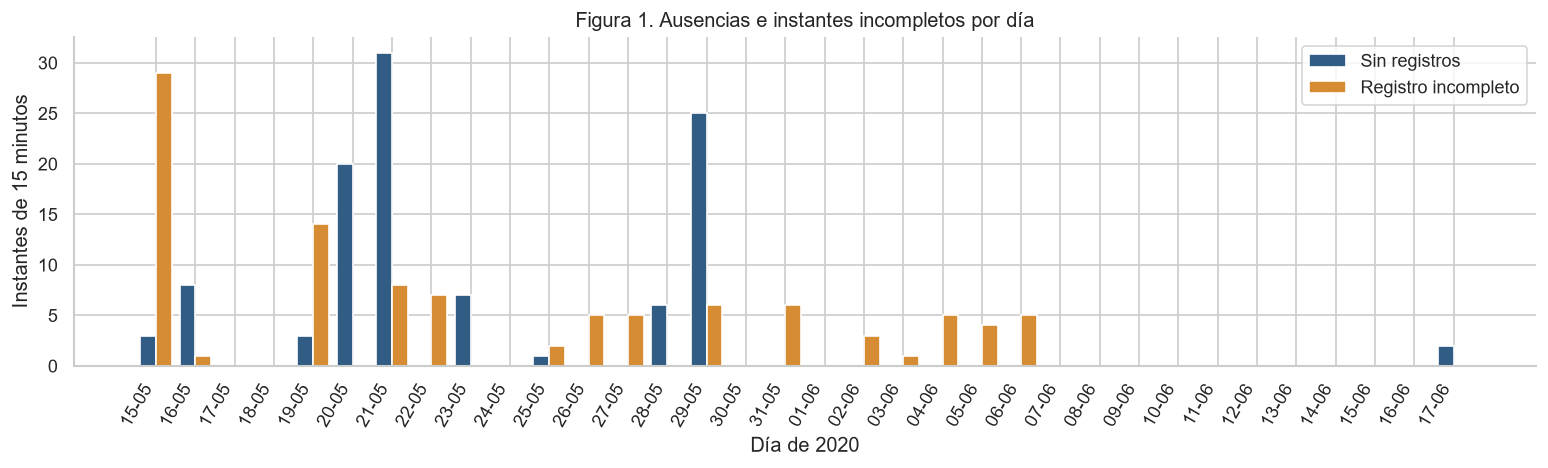

In [6]:
cobertura_dia = pd.DataFrame({
    'ausentes': (~planta['REGISTRO_PRESENTE']).resample('D').sum(),
    'incompletos': planta['INCOMPLETO'].resample('D').sum(),
    'completos': planta['GENERACION_COMPLETA'].resample('D').sum(),
})
cobertura_dia['cobertura_completa_%'] = 100 * cobertura_dia['completos'] / 96
display(cobertura_dia.round(2))
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(cobertura_dia))
ax.bar(x - .2, cobertura_dia['ausentes'], .4, color=AZUL, label='Sin registros')
ax.bar(x + .2, cobertura_dia['incompletos'], .4, color=NARANJA, label='Registro incompleto')
ax.set_xticks(x, labels=[f'{d:%d-%m}' for d in cobertura_dia.index], rotation=60, ha='right')
ax.set(title='Figura 1. Ausencias e instantes incompletos por día',
       xlabel='Día de 2020', ylabel='Instantes de 15 minutos')
ax.legend()
fig.tight_layout()
plt.show()

In [7]:
dia_mas_ausente = cobertura_dia['ausentes'].idxmax()
display(Markdown(
    f'**Lectura de la figura 1.** Faltan por completo **{resumen["Instantes sin registros"]} instantes** '
    f'y otros **{resumen["Instantes recibidos incompletos"]}** tienen información parcial. '
    f'La serie con 22 inversores cubre **{100 * serie.notna().mean():.2f}%** de la rejilla. '
    f'El mayor número de instantes ausentes corresponde al **{dia_mas_ausente:%d-%m}** '
    f'({int(cobertura_dia.loc[dia_mas_ausente, "ausentes"])}). '
    'Los huecos no se convierten en cero: hacerlo produciría una caída de generación artificial.'
))
# Cuantificar tramos consecutivos sin un registro completo. La rejilla ya es regular.
sin_completo = serie.isna()
segmentos = sin_completo.ne(sin_completo.shift()).cumsum()
filas_tramos = []
for _, tramo in sin_completo[sin_completo].groupby(segmentos[sin_completo]):
    filas_tramos.append({'inicio': tramo.index.min(), 'fin': tramo.index.max(),
                         'instantes': len(tramo), 'minutos_representados': len(tramo) * 15})
tramos = pd.DataFrame(filas_tramos).sort_values('instantes', ascending=False)
display(tramos.head(10))
print('La duración representa intervalos faltantes, no prueba una desconexión física de los equipos.')

**Lectura de la figura 1.** Faltan por completo **106 instantes** y otros **101** tienen información parcial. La serie con 22 inversores cubre **93.66%** de la rejilla. El mayor número de instantes ausentes corresponde al **21-05** (31). Los huecos no se convierten en cero: hacerlo produciría una caída de generación artificial.

,inicio,fin,instantes,minutos_representados
9,2020-05-20 23:00:00,2020-05-21 07:30:00,35,525
19,2020-05-28 22:30:00,2020-05-29 06:00:00,31,465
8,2020-05-20 13:30:00,2020-05-20 17:15:00,16,240
7,2020-05-19 16:30:00,2020-05-19 19:45:00,14,210
5,2020-05-15 23:15:00,2020-05-16 02:00:00,12,180
4,2020-05-15 19:00:00,2020-05-15 21:00:00,9,135
2,2020-05-15 02:00:00,2020-05-15 04:00:00,9,135
10,2020-05-21 18:15:00,2020-05-21 20:00:00,8,120
11,2020-05-22 18:45:00,2020-05-22 20:15:00,7,105
20,2020-05-29 18:30:00,2020-05-29 19:45:00,6,90


La duración representa intervalos faltantes, no prueba una desconexión física de los equipos.


,registros,ausentes_sobre_rejilla,cobertura_%
SOURCE_KEY,,,
YxYtjZvoooNbGkE,3104,160,95.10
3PZuoBAID5Wc2HD,3118,146,95.53
WRmjgnKYAwPKWDb,3118,146,95.53
1IF53ai7Xc0U56Y,3119,145,95.56
adLQvlD726eNBSB,3119,145,95.56
zBIq5rxdHJRwDNY,3119,145,95.56
ZoEaEvLYb1n2sOq,3123,141,95.68
McdE0feGgRqW7Ca,3124,140,95.71
sjndEbLyjtCKgGv,3124,140,95.71


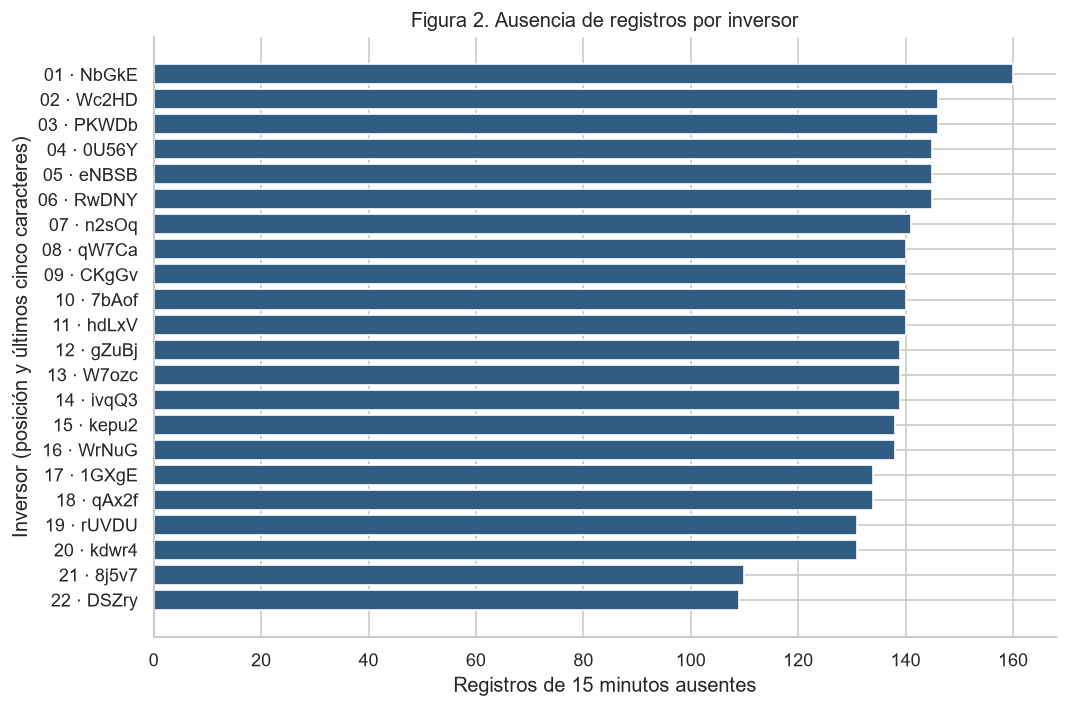

**Lectura de la figura 2.** La ausencia incluye tanto los huecos comunes a toda la planta como los reportes individuales que faltan. La tabla permite identificar equipos con menor cobertura; por sí sola no distingue una falla del inversor de una pérdida de comunicación.

In [8]:
registros_inversor = generacion.groupby('SOURCE_KEY').size().sort_values()
faltantes_inversor = len(rejilla) - registros_inversor
tabla_inversores = pd.DataFrame({'registros': registros_inversor,
                                 'ausentes_sobre_rejilla': faltantes_inversor,
                                 'cobertura_%': 100 * registros_inversor / len(rejilla)})
display(tabla_inversores.round(2))
# Etiquetas cortas para el gráfico; la tabla conserva los identificadores completos.
etiquetas = [f'{i+1:02d} · {str(k)[-5:]}' for i, k in enumerate(tabla_inversores.index)]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(np.arange(len(tabla_inversores)), tabla_inversores['ausentes_sobre_rejilla'], color=AZUL)
ax.set_yticks(np.arange(len(tabla_inversores)), labels=etiquetas)
ax.set(title='Figura 2. Ausencia de registros por inversor', xlabel='Registros de 15 minutos ausentes',
       ylabel='Inversor (posición y últimos cinco caracteres)')
ax.invert_yaxis()
fig.tight_layout()
plt.show()
display(Markdown(
    '**Lectura de la figura 2.** La ausencia incluye tanto los huecos comunes a toda la planta '
    'como los reportes individuales que faltan. La tabla permite identificar equipos con menor '
    'cobertura; por sí sola no distingue una falla del inversor de una pérdida de comunicación.'
))

## 5. EDA: serie temporal y distribución de la potencia

Las gráficas usan `AC_PLANTA_KW` con instantes completos. Los huecos se dibujan como interrupciones. Este EDA es descriptivo de los datos recibidos; **no mide precisión predictiva**.

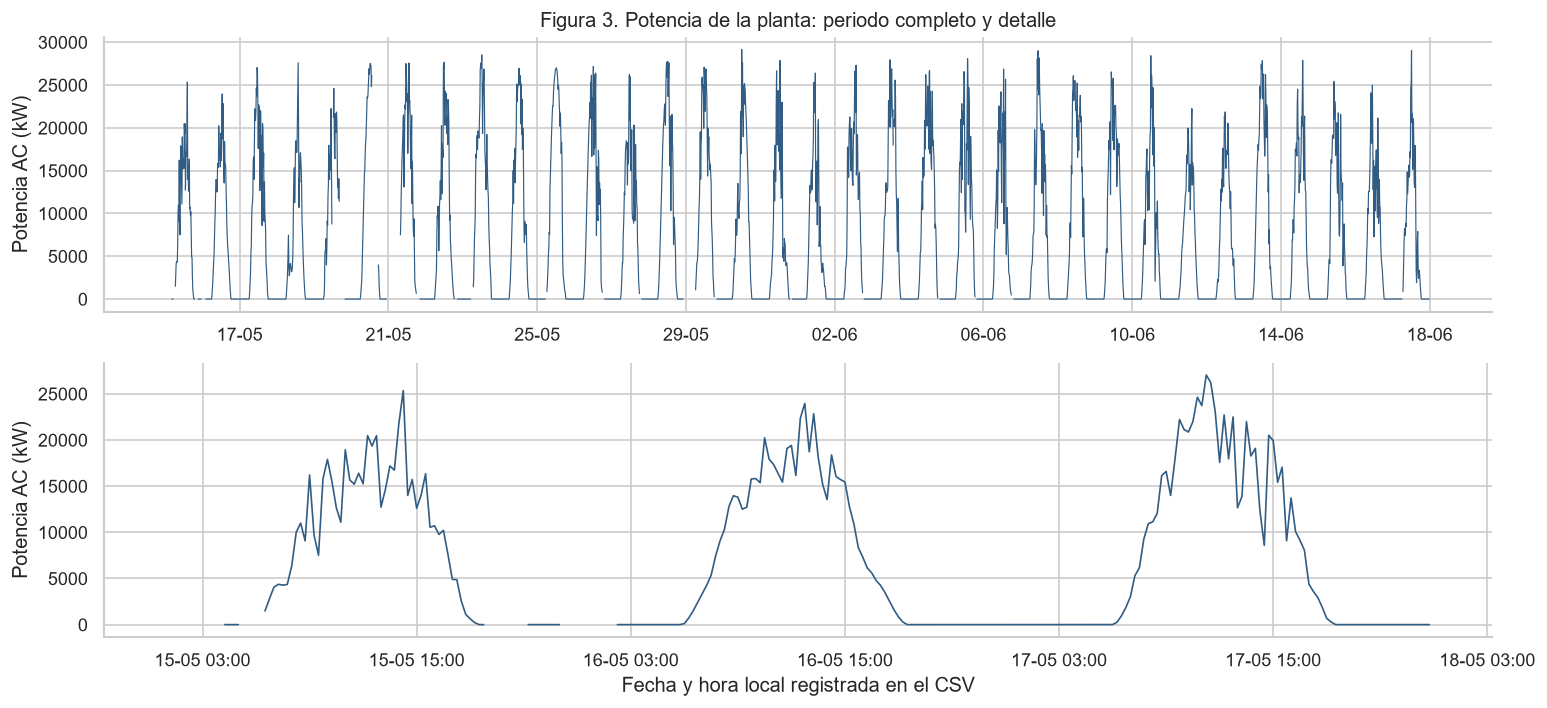

**Lectura de la figura 3.** La potencia máxima con los 22 inversores es **29,150.2 kW** en **30-05 12:00**. Se observan ciclos de generación y periodos de potencia cero. Las diferencias entre días no se atribuyen todavía a nubes o temperatura: faltan las mediciones meteorológicas. Un hueco en la curva indica falta de una medición completa, no potencia igual a cero.

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), gridspec_kw={'height_ratios': [1, 1]})
axes[0].plot(serie.index, serie, lw=.7, color=AZUL)
axes[0].set(title='Figura 3. Potencia de la planta: periodo completo y detalle', ylabel='Potencia AC (kW)')
axes[0].xaxis.set_major_locator(mdates.DayLocator(interval=4))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
detalle = serie.loc[inicio:inicio + pd.Timedelta(days=3) - pd.Timedelta(minutes=15)]
axes[1].plot(detalle.index, detalle, lw=1, color=AZUL)
axes[1].set(ylabel='Potencia AC (kW)', xlabel='Fecha y hora local registrada en el CSV')
axes[1].xaxis.set_major_locator(mdates.HourLocator(interval=12))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m %H:%M'))
fig.tight_layout()
plt.show()
positiva = serie[serie > 0]
display(Markdown(
    f'**Lectura de la figura 3.** La potencia máxima con los 22 inversores es '
    f'**{serie.max():,.1f} kW** en **{serie.idxmax():%d-%m %H:%M}**. '
    'Se observan ciclos de generación y periodos de potencia cero. '
    'Las diferencias entre días no se atribuyen todavía a nubes o temperatura: faltan las mediciones meteorológicas. '
    'Un hueco en la curva indica falta de una medición completa, no potencia igual a cero.'
))

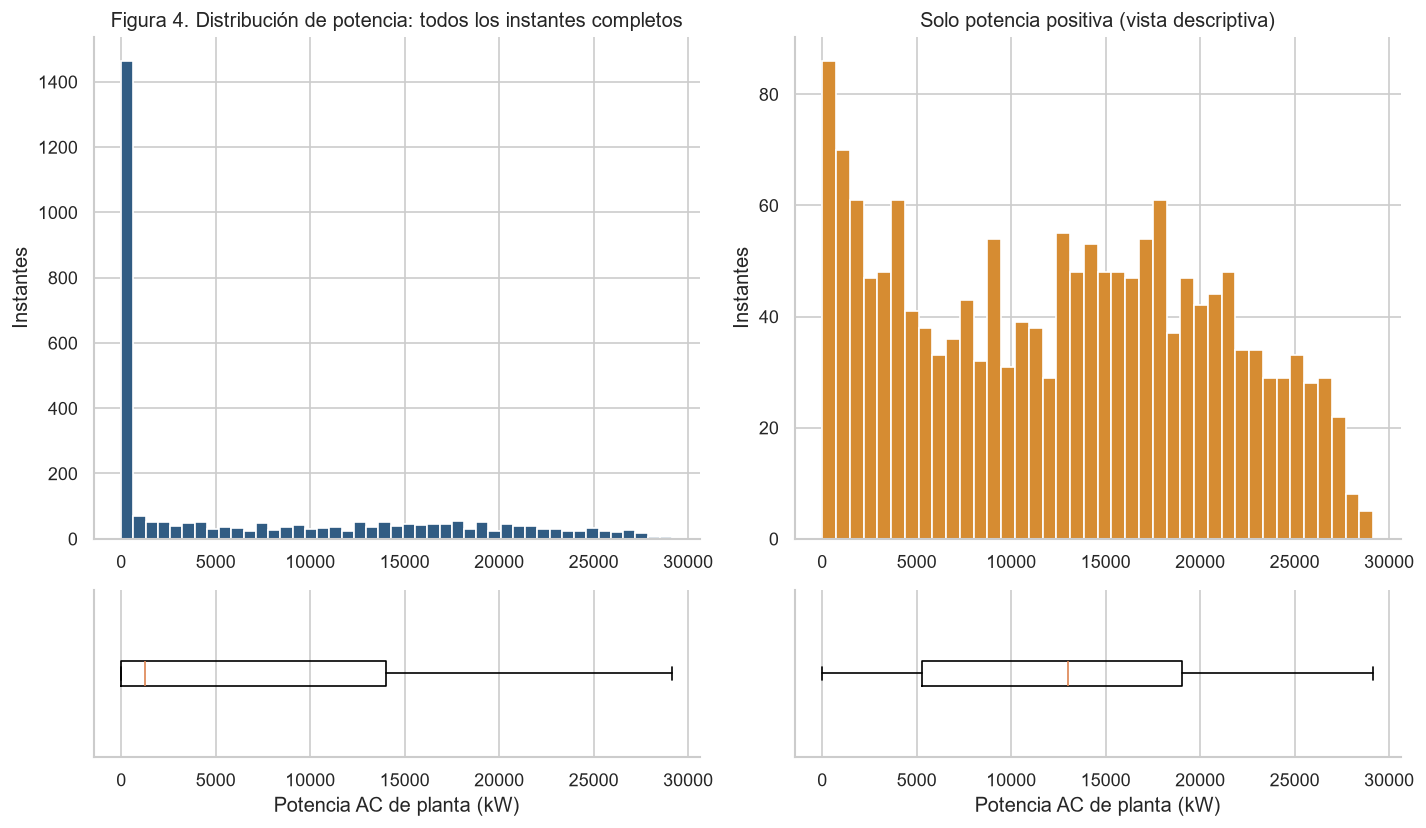

,todos_completos,solo_potencia_positiva
count,3057.00,1670.00
mean,6915.15,12658.45
std,8660.95,8037.73
min,0.00,1.72
25%,0.00,5257.17
50%,1269.98,13017.66
75%,14006.45,19033.93
max,29150.21,29150.21


**Lectura de la figura 4.** Hay **1387 instantes completos con potencia cero** (45.4% de los completos). Separar la vista de potencia positiva permite ver la distribución que la masa de ceros oculta. **Potencia positiva no equivale al filtro de horas de sol** exigido por la consigna: también puede haber potencia cero con irradiación, y debe investigarse cuando llegue el sensor. Los puntos fuera de las cajas no se eliminan automáticamente.

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), gridspec_kw={'height_ratios': [3, 1]})
axes[0, 0].hist(serie.dropna(), bins=45, color=AZUL, edgecolor='white')
axes[0, 0].set(title='Figura 4. Distribución de potencia: todos los instantes completos', ylabel='Instantes')
axes[0, 1].hist(positiva, bins=40, color=NARANJA, edgecolor='white')
axes[0, 1].set(title='Solo potencia positiva (vista descriptiva)', ylabel='Instantes')
axes[1, 0].boxplot(serie.dropna(), orientation='horizontal', showfliers=True)
axes[1, 1].boxplot(positiva, orientation='horizontal', showfliers=True)
for ax in axes[1]:
    ax.set(xlabel='Potencia AC de planta (kW)', yticks=[])
fig.tight_layout()
plt.show()
display(pd.DataFrame({'todos_completos': serie.describe(),
                      'solo_potencia_positiva': positiva.describe()}).round(2))
display(Markdown(
    f'**Lectura de la figura 4.** Hay **{int(serie.eq(0).sum())} instantes completos con potencia cero** '
    f'({100 * serie.eq(0).sum() / serie.notna().sum():.1f}% de los completos). '
    'Separar la vista de potencia positiva permite ver la distribución que la masa de ceros oculta. '
    '**Potencia positiva no equivale al filtro de horas de sol** exigido por la consigna: '
    'también puede haber potencia cero con irradiación, y debe investigarse cuando llegue el sensor. '
    'Los puntos fuera de las cajas no se eliminan automáticamente.'
))

## 6. EDA: perfil diario y mapa día-hora

El perfil compara el mismo cuarto de hora en distintos días. La banda representa los cuartiles 25 y 75, **no un intervalo de confianza**. Los conteos por cuarto de hora permiten ver cuánto respaldo tiene cada punto del perfil.

,q25,mediana,q75,n
DATE_TIME,,,,
0.0,0.00,0.00,0.00,30
1.0,0.00,0.00,0.00,31
2.0,0.00,0.00,0.00,30
3.0,0.00,0.00,0.00,31
4.0,0.00,0.00,0.00,31
5.0,0.00,0.00,0.00,32
6.0,109.16,164.98,216.21,29
7.0,3119.56,3717.30,4209.03,33
8.0,7241.23,9257.71,10840.92,34


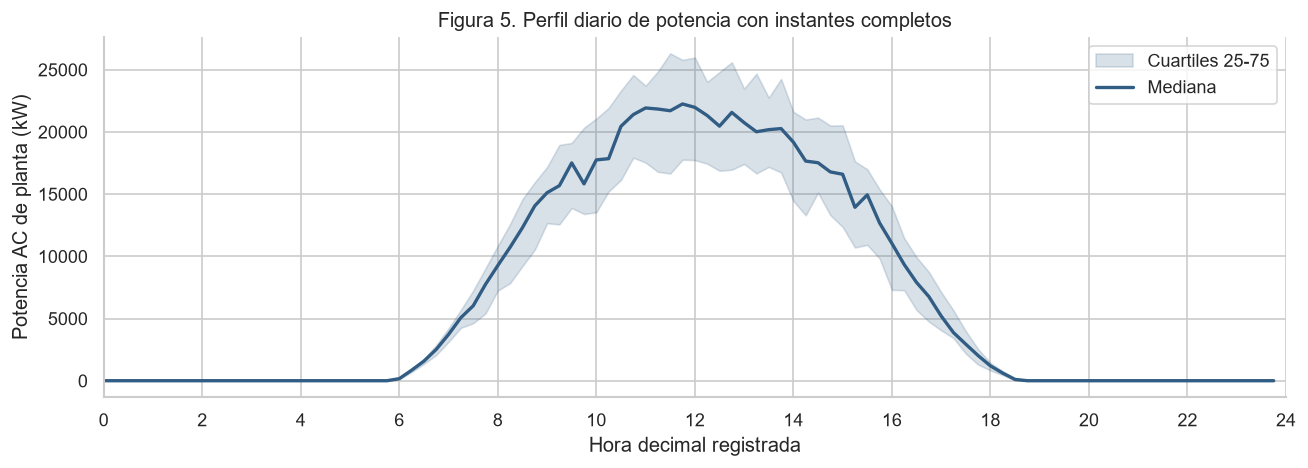

**Lectura de la figura 5.** La mediana del perfil alcanza su máximo a las **11:45**. Cada cuarto de hora tiene entre **23 y 34** mediciones completas. La amplitud de la banda describe variabilidad entre días; su causa debe contrastarse con los sensores y no inferirse solo del perfil.

In [11]:
hora_decimal = pd.Series(serie.index.hour + serie.index.minute / 60, index=serie.index)
perfil = serie.groupby(hora_decimal).quantile([.25, .5, .75]).unstack()
perfil.columns = ['q25', 'mediana', 'q75']
perfil['n'] = serie.groupby(hora_decimal).count()
display(perfil.iloc[::4].round(2))  # La gráfica usa los 96 cuartos de hora.
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(perfil.index.to_numpy(), perfil['q25'].to_numpy(), perfil['q75'].to_numpy(),
                color=AZUL, alpha=.18, label='Cuartiles 25-75')
ax.plot(perfil.index, perfil['mediana'], color=AZUL, lw=2, label='Mediana')
ax.set(title='Figura 5. Perfil diario de potencia con instantes completos',
       xlabel='Hora decimal registrada', ylabel='Potencia AC de planta (kW)',
       xticks=np.arange(0, 25, 2), xlim=(0, 24))
ax.legend()
fig.tight_layout()
plt.show()
hora_pico = float(perfil['mediana'].idxmax())
display(Markdown(
    f'**Lectura de la figura 5.** La mediana del perfil alcanza su máximo a las '
    f'**{int(hora_pico):02d}:{round((hora_pico % 1) * 60):02d}**. '
    f'Cada cuarto de hora tiene entre **{int(perfil["n"].min())} y {int(perfil["n"].max())}** '
    'mediciones completas. La amplitud de la banda describe variabilidad entre días; '
    'su causa debe contrastarse con los sensores y no inferirse solo del perfil.'
))

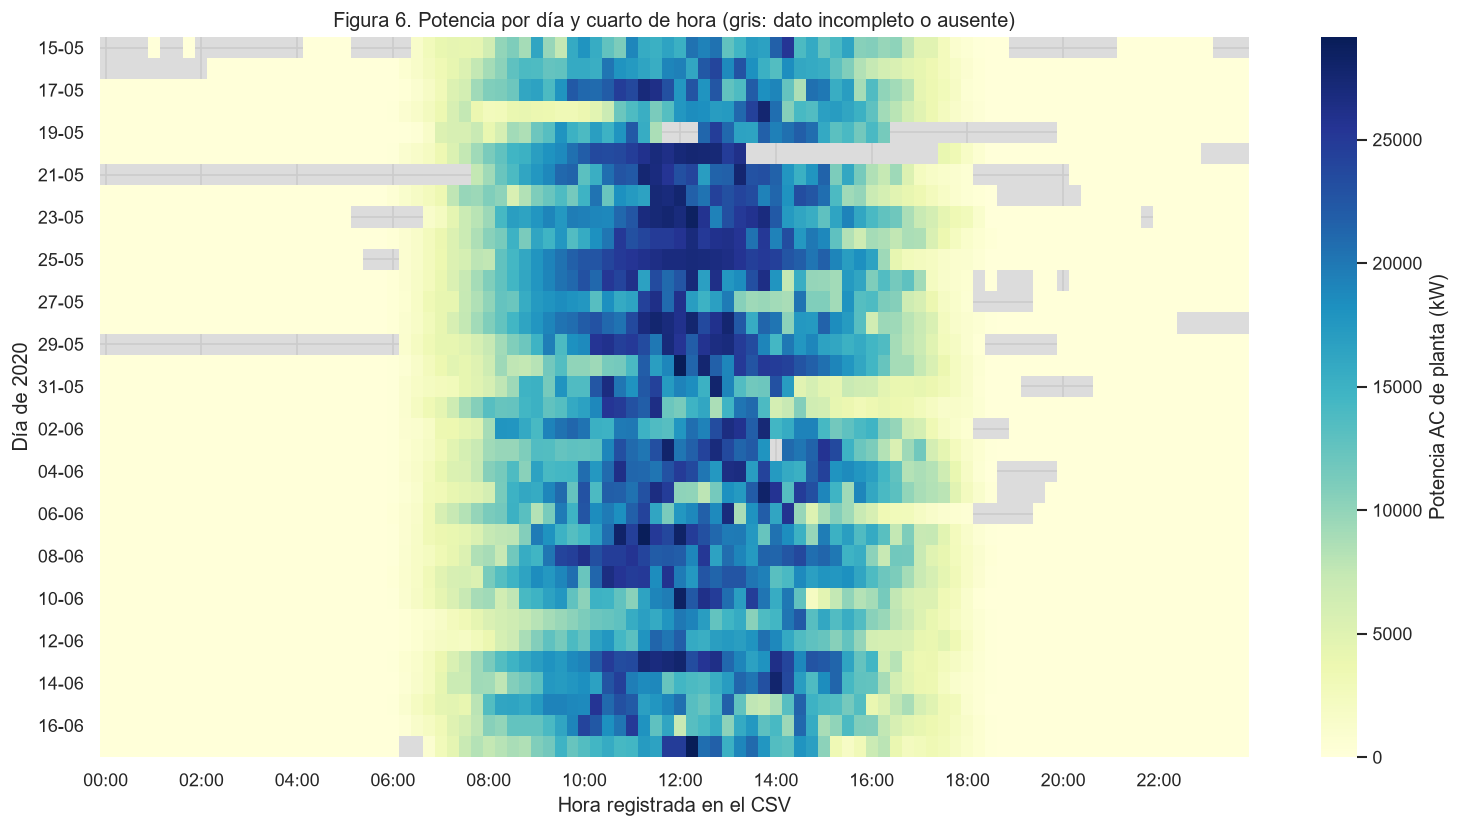

**Lectura de la figura 6.** El mapa permite comparar la forma del día entre fechas y localizar los huecos. El gris identifica ausencia de una medición completa; los tonos claros dentro de la escala representan potencia baja o cero. Un día menos intenso solo es comparable si se revisa también su cobertura. No se etiqueta un día como nublado sin el sensor.

,instantes_completos,media_kw,mediana_kw,maximo_kw,cobertura_%
DATE_TIME,,,,,
2020-05-15,64,8596.04,9386.45,25352.55,66.67
2020-05-16,87,6532.87,2414.70,23955.61,90.62
2020-05-17,96,6885.16,268.50,27034.63,100.00
2020-05-18,96,4905.93,583.38,27601.92,100.00
2020-05-19,79,6411.15,0.00,24603.55,82.29
2020-05-20,76,6909.01,0.00,27515.06,79.17
2020-05-21,57,11624.02,12291.14,27574.48,59.38
2020-05-22,89,7054.27,1710.03,27677.36,92.71
2020-05-23,89,8380.72,2173.41,28516.90,92.71


Las medias diarias describen solo instantes observados completos; días con cobertura distinta no son equivalentes.


In [12]:
mapa = pd.DataFrame({'dia': serie.index.normalize(), 'hora': hora_decimal.to_numpy(),
                     'AC_PLANTA_KW': serie.to_numpy()}).pivot(index='dia', columns='hora', values='AC_PLANTA_KW')
fig, ax = plt.subplots(figsize=(13, 7))
ax.set_facecolor('#DCDCDC')
sns.heatmap(mapa, cmap='YlGnBu', ax=ax, vmin=0, xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'Potencia AC de planta (kW)'})
columnas = np.arange(0, mapa.shape[1], 8)
filas = np.arange(0, len(mapa), 2)
ax.set_xticks(columnas + .5, labels=[f'{int(mapa.columns[i]):02d}:00' for i in columnas])
ax.set_yticks(filas + .5, labels=[f'{mapa.index[i]:%d-%m}' for i in filas], rotation=0)
ax.set(title='Figura 6. Potencia por día y cuarto de hora (gris: dato incompleto o ausente)',
       xlabel='Hora registrada en el CSV', ylabel='Día de 2020')
fig.tight_layout()
plt.show()
display(Markdown(
    '**Lectura de la figura 6.** El mapa permite comparar la forma del día entre fechas y localizar '
    'los huecos. El gris identifica ausencia de una medición completa; los tonos claros dentro '
    'de la escala representan potencia baja o cero. Un día menos intenso solo es comparable '
    'si se revisa también su cobertura. No se etiqueta un día como nublado sin el sensor.'
))
resumen_diario = serie.resample('D').agg(['count', 'mean', 'median', 'max'])
resumen_diario.columns = ['instantes_completos', 'media_kw', 'mediana_kw', 'maximo_kw']
resumen_diario['cobertura_%'] = 100 * resumen_diario['instantes_completos'] / 96
display(resumen_diario.round(2))
print('Las medias diarias describen solo instantes observados completos; días con cobertura distinta no son equivalentes.')

## 7. Revisión de la escala DC/AC

Esta comparación se hace a nivel de inversor, con `AC_POWER > 1 kW` y `DC_POWER > 0`, para evitar la división por cero y la inestabilidad cerca de cero. La tabla y el histograma usan todos esos registros; la dispersión utiliza una muestra fija de hasta 4.000 puntos para ser legible.

,DC/AC
count,36817.0000
mean,10.2336
std,0.0481
min,9.3816
1%,10.1734
25%,10.2026
50%,10.2202
75%,10.2481
99%,10.3715
max,10.4655


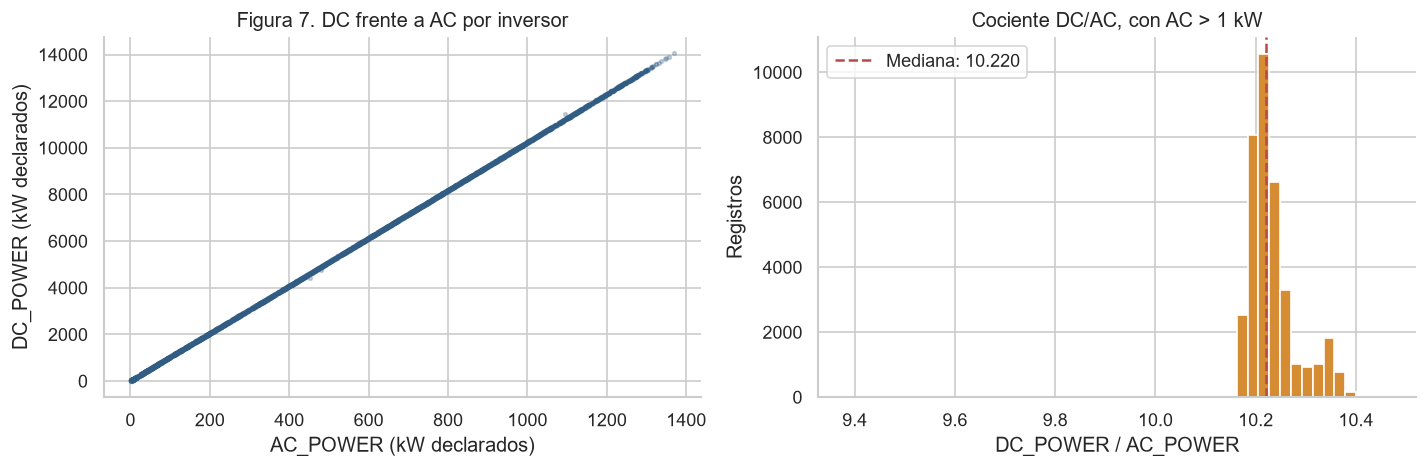

**Lectura de la figura 7.** La mediana DC/AC es **10.2202**. La diferencia de magnitud requiere verificar unidades o escala antes de interpretar una eficiencia física. Este avance no divide DC por diez ni modifica AC. `DC_POWER` y los acumulados de energía no se utilizarán como predictores, conforme a la consigna; aquí se revisan por calidad de los datos.

In [13]:
validos_cociente = generacion.loc[(generacion['AC_POWER'] > 1) & (generacion['DC_POWER'] > 0)].copy()
validos_cociente['DC_sobre_AC'] = validos_cociente['DC_POWER'] / validos_cociente['AC_POWER']
ratio = validos_cociente['DC_sobre_AC']
display(ratio.describe(percentiles=[.01, .25, .5, .75, .99]).round(4).to_frame('DC/AC'))
muestra = validos_cociente.sample(n=min(4000, len(validos_cociente)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(muestra['AC_POWER'], muestra['DC_POWER'], s=5, alpha=.25, color=AZUL)
axes[0].set(title='Figura 7. DC frente a AC por inversor', xlabel='AC_POWER (kW declarados)',
            ylabel='DC_POWER (kW declarados)')
axes[1].hist(ratio, bins=50, color=NARANJA, edgecolor='white')
axes[1].axvline(ratio.median(), color=ROJO, linestyle='--', label=f'Mediana: {ratio.median():.3f}')
axes[1].set(title='Cociente DC/AC, con AC > 1 kW', xlabel='DC_POWER / AC_POWER', ylabel='Registros')
axes[1].legend()
fig.tight_layout()
plt.show()
display(Markdown(
    f'**Lectura de la figura 7.** La mediana DC/AC es **{ratio.median():.4f}**. '
    'La diferencia de magnitud requiere verificar unidades o escala antes de interpretar una eficiencia física. '
    'Este avance no divide DC por diez ni modifica AC. `DC_POWER` y los acumulados de energía '
    'no se utilizarán como predictores, conforme a la consigna; aquí se revisan por calidad de los datos.'
))

## 8. Candidatos atípicos: IQR por hora y revisión pendiente

Un valor raro para una hora puede ser normal para otra. Se usa la regla de la guía por **hora del día**, con `k = 3`, como regla exploratoria revisable:

$$IQR_h=Q_{0.75,h}-Q_{0.25,h},\qquad
L_h=Q_{0.25,h}-3IQR_h,\quad U_h=Q_{0.75,h}+3IQR_h.$$

Para no estimar estos límites con los últimos días, se toma como corte de trabajo el primer día del último 20% del periodo. No se entrena ningún modelo. Los cuartiles por hora se calculan solo con los primeros días y se aplican al resto para señalar candidatos. **La marca estadística no es prueba de un error físico.** Sin el sensor no se puede contrastar potencia con irradiación; no se elimina ni imputa un valor por esta regla.

Corte de trabajo: 2020-06-11 | Días iniciales: 27 | Días finales: 7
Candidatos IQR por hora: 0 | No se elimina ninguno.


,q25,q75,n,inferior,superior
DATE_TIME,,,,,
0,0.00,0.00,92,0.00,0.00
1,0.00,0.00,94,0.00,0.00
2,0.00,0.00,95,0.00,0.00
3,0.00,0.00,96,0.00,0.00
4,0.00,0.00,99,0.00,0.00
5,0.00,0.00,92,0.00,0.00
6,469.11,1913.50,97,-3864.06,6246.67
7,4217.06,7208.55,105,-4757.40,16183.01
8,9077.67,14009.88,108,-5718.95,28806.50


,AC_PLANTA_KW,inferior,superior,periodo,decision
DATE_TIME,,,,,


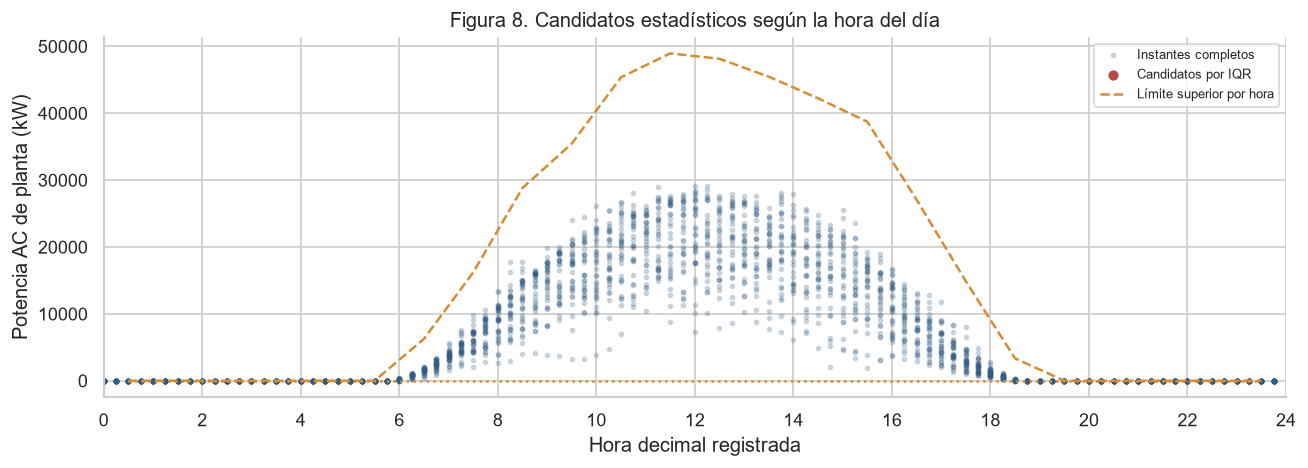

**Lectura de la figura 8.** La regla marca **0 candidatos**. Una marca estadística no confirma un error físico: no se descartan observaciones por esta regla. Los límites son constantes dentro de cada hora; las líneas solo ayudan a ver su evolución. El límite inferior se recorta a cero únicamente al dibujarlo, no al calcular las marcas. El corte **11-06-2020** deja 27 días iniciales y 7 finales. Este corte y k=3 quedan sujetos a revisión del equipo.

In [14]:
dias = pd.date_range(inicio.normalize(), fin.normalize(), freq='D')
numero_dias_train = int(np.floor(.8 * len(dias)))
FECHA_CORTE = dias[numero_dias_train]
serie_train = serie.loc[serie.index < FECHA_CORTE]
K_IQR = 3.0
regla_hora = serie_train.groupby(serie_train.index.hour).agg(
    q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n='count')
regla_hora['inferior'] = regla_hora['q25'] - K_IQR * (regla_hora['q75'] - regla_hora['q25'])
regla_hora['superior'] = regla_hora['q75'] + K_IQR * (regla_hora['q75'] - regla_hora['q25'])
limites = regla_hora[['inferior', 'superior']].reindex(serie.index.hour).set_axis(serie.index)
candidato = serie.notna() & ((serie < limites['inferior']) | (serie > limites['superior']))
tabla_candidatos = planta.loc[candidato, ['AC_PLANTA_KW']].join(limites)
tabla_candidatos['periodo'] = np.where(tabla_candidatos.index < FECHA_CORTE,
                                      'primeros días', 'últimos días reservados')
tabla_candidatos['decision'] = 'Conservar; revisar con sensor y regla física'
print('Corte de trabajo:', FECHA_CORTE.date(), '| Días iniciales:', numero_dias_train,
      '| Días finales:', len(dias) - numero_dias_train)
print('Candidatos IQR por hora:', int(candidato.sum()), '| No se elimina ninguno.')
display(regla_hora.round(2))
display(tabla_candidatos.head(20).round(2))
fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(hora_decimal, serie, s=6, color=AZUL, alpha=.2, label='Instantes completos')
ax.scatter(hora_decimal.loc[candidato], serie.loc[candidato], s=26, color=ROJO,
           label='Candidatos por IQR')
ax.plot(regla_hora.index + .5, regla_hora['superior'], color=NARANJA, ls='--', label='Límite superior por hora')
ax.plot(regla_hora.index + .5, regla_hora['inferior'].clip(lower=0), color=NARANJA, ls=':')
ax.set(title='Figura 8. Candidatos estadísticos según la hora del día',
       xlabel='Hora decimal registrada', ylabel='Potencia AC de planta (kW)',
       xlim=(0, 24), xticks=np.arange(0, 25, 2))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(Markdown(
    f'**Lectura de la figura 8.** La regla marca **{int(candidato.sum())} candidatos**. '
    'Una marca estadística no confirma un error físico: no se descartan observaciones por esta regla. '
    'Los límites son constantes dentro de cada hora; las líneas solo ayudan a ver su evolución. '
    'El límite inferior se recorta a cero únicamente al dibujarlo, no al calcular las marcas. '
    f'El corte **{FECHA_CORTE:%d-%m-%Y}** deja {numero_dias_train} días iniciales y '
    f'{len(dias) - numero_dias_train} finales. Este corte y k=3 quedan sujetos a revisión del equipo.'
))

## 9. Memoria temporal: rezagos y autocorrelación

Se desplaza la serie **por fecha**, como indica el Anexo B, antes de cualquier filtro de potencia positiva. Si falta el valor de hace 15 minutos, el rezago permanece vacío. No se salta al registro disponible anterior ni se enlaza la última medición de ayer con la primera de hoy.

Para explorar el aporte de los rezagos se usan solo los primeros días. La autocorrelación se calcula con pares observados completos y se informa su tamaño. Se compara la serie original con su anomalía respecto al promedio de cada cuarto de hora de ese mismo periodo: el ciclo diario puede explicar parte de una correlación alta.

,pares_observados,correlacion_todos,pares_ambos_positivos,correlacion_ambos_positivos
rezago_minutos,,,,
15,2360,0.9590,1287,0.9084
30,2340,0.9328,1258,0.8430
60,2303,0.8810,1201,0.6996
1440,2146,0.8987,1219,0.7808


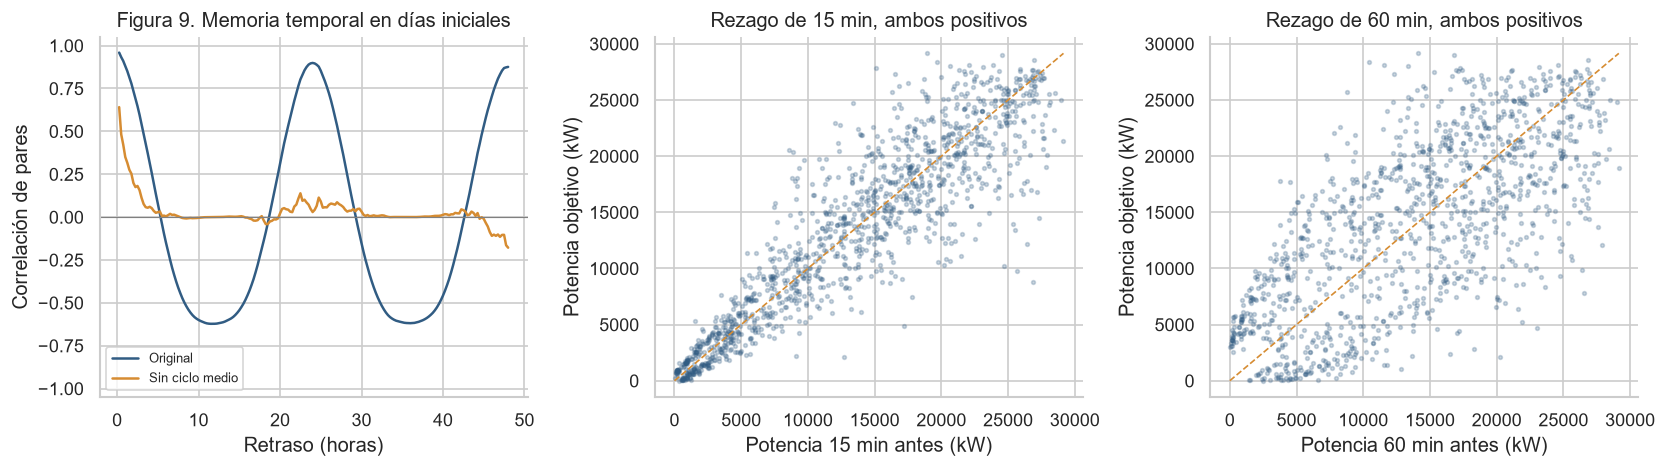

**Lectura de la figura 9.** La correlación a 15 minutos es **0.959** al incluir todos los pares y **0.908** cuando ambos valores son positivos. La diferencia recuerda el efecto de los ceros y del ciclo diario. Potencia positiva sigue siendo una vista descriptiva, no la definición final de horas de sol. Estas correlaciones justifican examinar la historia reciente y comparar contra persistencia; no son accuracy ni F1, ni demuestran que un clasificador funcionará en datos nuevos.

In [15]:
def valor_pasado_por_fecha(s, pasos):
    """Cada valor de s(t) se asocia a t + pasos*15 min y se alinea a las fechas originales."""
    return s.shift(pasos, freq=FRECUENCIA).reindex(s.index)

rezagos = pd.DataFrame(index=serie_train.index)
for paso in [1, 2, 4, 96]:
    rezagos[f'lag{paso}'] = valor_pasado_por_fecha(serie_train, paso)
filas_correlacion = []
for paso in [1, 2, 4, 96]:
    anterior = rezagos[f'lag{paso}']
    pares = serie_train.notna() & anterior.notna()
    pares_positivos = pares & serie_train.gt(0) & anterior.gt(0)
    filas_correlacion.append({'rezago_minutos': paso * 15,
        'pares_observados': int(pares.sum()),
        'correlacion_todos': serie_train[pares].corr(anterior[pares]),
        'pares_ambos_positivos': int(pares_positivos.sum()),
        'correlacion_ambos_positivos': serie_train[pares_positivos].corr(anterior[pares_positivos])})
correlaciones_rezagos = pd.DataFrame(filas_correlacion).set_index('rezago_minutos')
display(correlaciones_rezagos.round(4))
hora_train = pd.Series(serie_train.index.hour + serie_train.index.minute / 60, index=serie_train.index)
promedio_hora_train = serie_train.groupby(hora_train).mean()
anomalia_train = serie_train - hora_train.map(promedio_hora_train)
pasos_acf = range(1, 193)
acf = pd.DataFrame({
    'serie': [serie_train.corr(valor_pasado_por_fecha(serie_train, k)) for k in pasos_acf],
    'sin_ciclo_medio': [anomalia_train.corr(valor_pasado_por_fecha(anomalia_train, k)) for k in pasos_acf],
}, index=pd.Index(pasos_acf, name='pasos'))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(acf.index / 4, acf['serie'], color=AZUL, label='Original')
axes[0].plot(acf.index / 4, acf['sin_ciclo_medio'], color=NARANJA, label='Sin ciclo medio')
axes[0].axhline(0, color='gray', lw=.7)
axes[0].set(title='Figura 9. Memoria temporal en días iniciales', xlabel='Retraso (horas)',
            ylabel='Correlación de pares', ylim=(-1.05, 1.05))
axes[0].legend(fontsize=8)
for ax, paso in zip(axes[1:], [1, 4]):
    anterior = rezagos[f'lag{paso}']
    mask = serie_train.gt(0) & anterior.gt(0)
    ax.scatter(anterior[mask], serie_train[mask], s=5, alpha=.25, color=AZUL)
    maximo = float(max(anterior[mask].max(), serie_train[mask].max()))
    ax.plot([0, maximo], [0, maximo], color=NARANJA, ls='--', lw=1)
    ax.set(title=f'Rezago de {paso * 15} min, ambos positivos',
           xlabel=f'Potencia {paso * 15} min antes (kW)', ylabel='Potencia objetivo (kW)')
fig.tight_layout()
plt.show()
display(Markdown(
    f'**Lectura de la figura 9.** La correlación a 15 minutos es '
    f'**{correlaciones_rezagos.loc[15, "correlacion_todos"]:.3f}** al incluir todos los pares y '
    f'**{correlaciones_rezagos.loc[15, "correlacion_ambos_positivos"]:.3f}** cuando ambos valores son positivos. '
    'La diferencia recuerda el efecto de los ceros y del ciclo diario. '
    'Potencia positiva sigue siendo una vista descriptiva, no la definición final de horas de sol. '
    'Estas correlaciones justifican examinar la historia reciente y comparar contra persistencia; '
    'no son accuracy ni F1, ni demuestran que un clasificador funcionará en datos nuevos.'
))

## 10. Pendientes del sensor y de la unión

El EDA completo del Proyecto 3 requiere además:

1. Convertir las fechas del sensor con su formato propio y contar ausencias, duplicados y sensores distintos.
2. Verificar que el identificador de planta coincida y unir por fecha con una relación uno a uno después de agregar generación; cuantificar fechas presentes solo en un archivo.
3. Analizar rangos y valores congelados de irradiación y temperaturas; revisar potencia cero cuando hay sol.
4. Justificar un umbral de irradiación para el análisis de horas de sol. No sustituir ese criterio por `AC > 0` en el modelo final.
5. Graficar potencia frente a irradiación, temperatura del módulo frente a ambiente y correlaciones en horas de sol. Estas relaciones simultáneas describen física; no autorizan usar mediciones futuras como predictores.
6. Calcular correlaciones cruzadas con sensores rezagados. Construir los rezagos sobre la serie completa y filtrar después.
7. Definir los tres niveles con los terciles de entrenamiento en horas de sol y comparar su distribución en entrenamiento y prueba. Si se hace validación, revisar también cómo estimar los cortes dentro de cada pliegue.

No se inventan esos resultados a partir del archivo de generación. Tampoco se interpretan como meteorológicos los patrones diarios sin contrastarlos con el sensor.

In [16]:
if archivo_sensor.is_file():
    sensor_original = pd.read_csv(archivo_sensor)
    print('Sensor encontrado:', sensor_original.shape,
          'Completar la revisión y unión descrita arriba antes de modelar.')
    display(sensor_original.head())
else:
    print('PENDIENTE: datos/Plant_1_Weather_Sensor_Data.csv')
    print('La fuente Kaggle y la consigna especifican ese archivo para la Planta 1.')
# Confirmación de que este avance no cambió el archivo de entrada.
if hashlib.sha256(archivo_generacion.read_bytes()).hexdigest() != sha_generacion:
    raise RuntimeError('El archivo original cambió durante la ejecución.')
print('CSV de generación sin modificaciones: SHA-256 verificado.')

PENDIENTE: datos/Plant_1_Weather_Sensor_Data.csv
La fuente Kaggle y la consigna especifican ese archivo para la Planta 1.
CSV de generación sin modificaciones: SHA-256 verificado.


## 11. Resumen del avance y propuesta de tratamiento

Las siguientes son decisiones **exploratorias y revisables**, sin entrenar modelos ni sobrescribir datos:

| Situación | Tratamiento en este avance | Qué falta justificar |
|---|---|---|
| Fecha compartida por 22 inversores | Sumar AC y contar claves distintas; no borrar como duplicados | Mantener la revisión de claves al incorporar datos |
| Instante totalmente ausente | Rejilla con `NaN`, sin convertirlo a cero | Comparar opciones causales de tratamiento para modelado |
| Inversores faltantes | Conservar suma observada y marcar potencia completa como no disponible | Evaluar alternativas con sensor; no asumir que todos producían lo mismo |
| Potencia cero | Conservar | Distinguir noche, crepúsculo y posibles eventos con irradiación |
| Diferencia DC/AC | Documentar cociente y conservar registros | Verificar escala/unidades; no usar DC como predictor |
| Candidato IQR | Marcar y conservar | Revisión física y del equipo antes de corregir algo |
| Rezagos | Desplazamiento por tiempo, no por filas disponibles | Comparar variantes de potencia más clima cuando esté el sensor |
| Imputación | No aplicada | No usar observaciones futuras, no cruzar train/test y no fabricar etiquetas de evaluación |

**Lo que ya puede mostrarse hoy:** diagnóstico de la generación, cobertura por día e inversor, nueve figuras reproducibles y su lectura descriptiva. **Lo que aún no puede presentarse como completo:** EDA meteorológico y conjunto, clases diurnas y preparación final para modelado. Las observaciones de este notebook deben revisarlas los tres integrantes.

### Continuación del proyecto

Completar Tarea 1 y el EDA con sensor; revisar reglas de preparación; luego comparar clase mayoritaria, persistencia, regresión logística, KNN y árbol con validación cronológica y cinco particiones temporales. Imputación y escalado deberán ajustarse solo con entrenamiento mediante Pipeline. Informar accuracy, F1 macro, precisión/recall/F1 por clase y matriz de confusión; interpretar coeficientes, reglas e importancia de variables. No hay modelos o métricas de clasificación en esta versión.

El informe IEEE y las diapositivas se prepararán con los resultados reales. Mantener las evidencias de ética, impactos, formulación matemática y decisiones técnicas de las rúbricas. El informe final tiene máximo cinco páginas y la entrega del 24 de noviembre contiene notebook ejecutado, informe PDF y diapositivas PDF, sin CSV.

In [17]:
display(Markdown(
    '### Cifras comprobadas del avance\n\n'
    f'- **{len(generacion):,} registros**, **22 inversores** y **{len(dias)} días**.\n'
    f'- **{len(rejilla):,} instantes esperados**, **{len(instantes):,} recibidos**, '
    f'**{int((~planta["REGISTRO_PRESENTE"]).sum())} ausentes** y '
    f'**{int(planta["INCOMPLETO"].sum())} recibidos incompletos**.\n'
    f'- **{int(serie.notna().sum()):,} instantes completos** disponibles para el EDA de planta.\n'
    f'- **{int(candidato.sum())} candidatos IQR** conservados para revisar.\n'
    f'- Mediana DC/AC con AC > 1: **{ratio.median():.4f}**, sin corregir escala.\n'
    '- Sin imputación, entrenamiento de modelos ni cambios en los CSV originales.'
))

### Cifras comprobadas del avance

- **68,778 registros**, **22 inversores** y **34 días**.
- **3,264 instantes esperados**, **3,158 recibidos**, **106 ausentes** y **101 recibidos incompletos**.
- **3,057 instantes completos** disponibles para el EDA de planta.
- **0 candidatos IQR** conservados para revisar.
- Mediana DC/AC con AC > 1: **10.2202**, sin corregir escala.
- Sin imputación, entrenamiento de modelos ni cambios en los CSV originales.

## 12. Registro de colaboración con IA y fuentes

La consigna permite Nivel 3, colaboración con IAG. El registro documenta el apoyo; **no sustituye la revisión y comprensión de los integrantes**. Antes de entregar, todos deben poder explicar o modificar el código y completar la declaración del informe antes de referencias.

| Fecha | Herramienta | Apoyo solicitado | Verificación realizada | Revisión del equipo |
|---|---|---|---|---|
| 10-nov-2026 | ChatGPT, «Curso Analítica de Datos» | Lectura inicial de PDF, guía y CSV; planificación y capturas | Consigna y conteos contrastados con originales locales | Pendiente |
| 10-nov-2026 | Codex, este chat | Entorno y estructura inicial, documentación y diagnóstico | Hashes, dependencias, kernel y notebooks ejecutados | Pendiente |
| 11-nov-2026 | Codex, este chat | Simplificar a la estructura del curso; preparar avance de calidad y EDA | Reejecución del notebook, contraste de conteos, revisión visual de gráficas y publicación privada del avance sin CSV | Pendiente de lectura y ejecución por los tres integrantes |

**Fuentes usadas en este avance:** PDF local específico de Proyecto 3 (páginas 1, 3, 6-8 y anexos), guía HTML de la Semana 2, capturas recibidas del repositorio y el archivo local de generación. La página original de [Kaggle](https://www.kaggle.com/anikannal/solar-power-generation-data) confirma que los datos se distribuyen en pares generación/sensor para cada planta. Se intentó la descarga pública del sensor el 11 de noviembre; los endpoints consultados respondieron 404, por lo que no se incorporó un archivo alternativo sin verificar.

La configuración y el contexto detallados de la sesión anterior se conservan en un respaldo externo al proyecto, en `D:/Analitica de Datos/Respaldo_configuracion_2026-11-11/`. El trabajo activo se concentra aquí.

**Referencias IEEE de la Tarea 1:** todavía por investigar y verificar en sus documentos originales. No se han inventado citas, resultados meteorológicos, métricas de modelos ni conclusiones finales.

Repositorio privado: [MekiahxAndres/proyecto3-solar-planta1](https://github.com/MekiahxAndres/proyecto3-solar-planta1). El propietario añadirá a sus dos compañeros después; no se enviaron invitaciones.